# Difusão — como as músicas se espalham entre países e o que trava a travessia

A análise semântica mostrou que **US, BR, MX e ES convergem em conteúdo, mesmo entre as músicas exclusivas**,
enquanto o número de músicas compartilhadas cai. Este notebook trata a música como algo que **se espalha** entre
países para entender o mecanismo.

**Dados e resolução temporal**
- **MGDplus — chart diário**, 2017-01 a 2022-03: resolução de 1 dia (só os países do `finalData.csv`).
- **Charts de 4 semanas** (`spotify_top200_positions_*.csv`), 2018-05 a 2026: **1 semana amostrada a cada 4**.
  A data de entrada observada é a primeira amostra em que a música aparece, então ela atrasa em média ~2 semanas.
  Na seção 2, simulamos essa mesma amostragem no chart diário para saber se as estimativas grosseiras são
  comparáveis às finas.
- Usamos sempre o **mesmo conjunto de países**: os do `finalData.csv` que existem nas duas bases desde o início,
  para que "alcançou X países" signifique o mesmo em todos os anos.

**Seções**
1. **Modelo de Bass em duas fases** (chart diário, 2017–2021): o tempo é contado a partir do lançamento e os
   "adotantes" são países. A maior parte dos países adota **no dia do lançamento** (lançamento global simultâneo
   no Spotify), então separamos (a) a **fração simultânea** (adotada na 1ª semana) e (b) a **difusão gradual**
   depois disso, ajustada pelo Bass: **p** mede a adoção "externa" (o país adota sozinho, por marketing ou
   lançamento) e **q** mede a imitação (o país adota porque os outros já adotaram, o "contágio"). O SI é o caso
   particular p ≈ 0.
2. **Bass com os charts de 4 semanas** (2018–2025) e calibração contra o diário.
3. **Rede de liderança** (quem adota antes de quem): rede direcionada com teste binomial e correção FDR.
4. **O que faz uma música atravessar a barreira do idioma?** Modelo de alcance com toxicidade, idioma e
   popularidade prévia do artista (usa `dados/toxicidade.csv`, do `pipelineToxicidade.ipynb`).
5. **Semântica × difusão**: a música entra mais num país cujo chart é semanticamente parecido com ela?
   (usa os embeddings em `dados/embeddings/`, do `pipelineAnalise.ipynb`).

**Escopo (`UNIVERSO`):** por padrão (`top40`) só entram as músicas do `finalData.csv` e os países dele (6). Com
`UNIVERSO=top200`, entram todas as músicas do Top 200 desses mesmos países. Com só 6 países, `MIN_PAISES` caiu de 5
para 3 (alcançar 5 de 6 países seria quase "chegar a todos"); os valores de p e q não são comparáveis aos de rodadas
com dezenas de mercados.

Tudo roda em CPU. A primeira execução lê os ~2 GB do MGDplus (~1 min) e guarda um resumo em `dados/cache/`.

In [1]:
import os, hashlib, itertools, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from scipy.optimize import curve_fit
from scipy.stats import binomtest
from IPython.display import display

from comum import (RAIZ, PASTA_RES, PAISES, NOMES, LINGUA_PAIS, BLOCO_PAIS, ORDEM_BLOCOS, COR, SEQ, DIV, CORES_BLOCO,
                   aplica_estilo, plota_matriz, tendencia, carrega_4semanas, carrega_diario_entradas, datas_lancamento,
                   carrega_letras, idioma_simples, limpa_letra)

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)
aplica_estilo()

H_DIAS     = int(os.environ.get("H_DIAS", 180))    # janela de difusão após o lançamento
MIN_PAISES = int(os.environ.get("MIN_PAISES", 3))     # Bass só com músicas que chegaram a 3+ dos 6 países
N_BOOT     = int(os.environ.get("N_BOOT_BASS", 200))   # bootstrap das curvas de Bass
JANELA_ALC = 365                                   # janela do alcance (seções 4 e 5)
FDR        = 0.05
SEED       = 42
rng = np.random.default_rng(SEED)
PASTA_RES.mkdir(exist_ok=True)

# ---------- escopo da análise: só o que está no finalData.csv ----------
# UNIVERSO = "top40"  -> só as músicas do top 40 anual (finalData.csv), nos países do finalData.csv  (padrão)
# UNIVERSO = "top200" -> todas as músicas do Top 200 desses mesmos países
UNIVERSO = os.environ.get("UNIVERSO", "top40")
fd = carrega_letras()                                         # finalData.csv define países e músicas
PAISES_FD = [c for c in PAISES if c in set(fd["cc"])]
CHAVES_FD = set(fd["chave"])
if len(PAISES_FD) < len(PAISES):
    print("AVISO: países sem linhas no finalData.csv:", [c for c in PAISES if c not in PAISES_FD])

w = carrega_4semanas().dropna(subset=["chave"])
e = carrega_diario_entradas(paises=PAISES_FD)
e_pais = e
w_pais = w[w["cc"].isin(PAISES_FD)]                      # só os países do finalData.csv (sem filtro de música)
cob_fd = len(CHAVES_FD & set(w_pais["chave"])) / len(CHAVES_FD)
print(f"{len(CHAVES_FD):,} músicas no finalData.csv | {cob_fd:.0%} aparecem no Top 200 desses países")
if cob_fd < 0.5:
    print("AVISO: poucas músicas do finalData.csv foram encontradas nos charts: confira se a 'chave' (título + artista) bate.")
w = w_pais[w_pais["chave"].isin(CHAVES_FD)] if UNIVERSO == "top40" else w_pais
w_pop = w_pais                                  # popularidade prévia do artista (seção 4): todas as músicas dos 6 países
if UNIVERSO == "top40":
    e = e[e["chave"].isin(CHAVES_FD)]
# países com cobertura completa nas duas bases: assim "alcançou X países" significa o mesmo em todos os anos
ini_w = w_pais.groupby("cc")["week_end"].min()          # cobertura medida sem o filtro de músicas
cob = e_pais.groupby("cc").agg(ini=("primeira", "min"), fim=("ultima", "max"))
PAISES_DIF = sorted(set(ini_w[ini_w <= w_pais["week_end"].min()].index)
                    & set(cob[(cob["ini"] <= "2017-01-31") & (cob["fim"] >= "2022-03-01")].index),
                    key=lambda c: (ORDEM_BLOCOS.index(BLOCO_PAIS[c]), c))
print(f"{len(PAISES_DIF)} países na difusão:", " ".join(PAISES_DIF))
fora = sorted(set(PAISES_FD) - set(PAISES_DIF))
print("fora (entram tarde em alguma base):", " ".join(fora) or "nenhum")
if fora:
    print("AVISO: países do finalData.csv sem cobertura completa nas duas bases; a difusão usa só", " ".join(PAISES_DIF))
w = w[w["cc"].isin(PAISES_DIF)]
e = e[e["cc"].isin(PAISES_DIF)]
lanc, explicit = datas_lancamento()
AMOSTRAS = np.sort(w_pais["week_end"].unique())            # datas de amostra = as do chart, não só as das músicas filtradas
FIM_DIARIO, FIM_4S = e_pais["ultima"].max(), w_pais["week_end"].max()
print(f"chart diário até {FIM_DIARIO.date()} | charts de 4 semanas: {pd.Timestamp(AMOSTRAS[0]).date()} a {FIM_4S.date()}")

1,392 músicas no finalData.csv | 96% aparecem no Top 200 desses países
6 países na difusão: au us es mx br jp
fora (entram tarde em alguma base): nenhum


chart diário até 2022-03-13 | charts de 4 semanas: 2018-05-03 a 2026-10-08


## 1. Modelo de Bass no chart diário (duas fases)

Para cada música (todas as versões juntas, pela chave título + artista principal) e cada país: dias entre o
lançamento e a primeira entrada no Top 200. Cada música é normalizada pelo seu próprio alcance $m$ (países
alcançados em até `H_DIAS`); $\bar F(t)$ é a média dessas curvas em cada coorte de lançamento.

**Por que duas fases:** nas músicas que chegam a 5+ países, ~56% dos países adotam no próprio dia do lançamento
e ~80% na primeira semana. Isso é **transmissão** (lançamento global), não contágio, e um Bass único vira uma
exponencial com q = 0. Então:

- **Fração simultânea** $s = \bar F(\text{corte})$, com corte = 7 dias.
- **Difusão gradual:** $G(t) = (\bar F(\text{corte}+t) - s)/(1-s)$, ajustada pelo Bass
  $$G(t) = \frac{1 - e^{-(p+q)t}}{1 + \frac{q}{p} e^{-(p+q)t}}$$
  q alto em relação a p = curva em S = os países que chegam depois chegam **por imitação**.

Só entram músicas lançadas depois do início do chart (sem censura à esquerda) e com `H_DIAS` de observação depois
do lançamento (sem censura à direita). IC 95% por bootstrap das músicas.

In [2]:
def bass_F(t, p, q):
    x = np.exp(-(p + q) * t)
    return (1 - x) / (1 + (q / p) * x)


def matriz_adocao(entradas, col_data, ini, fim):
    """entradas: (cc, chave, data). Retorna DataFrame músicas × países com dias desde o lançamento (NaN = não adotou)."""
    x = entradas.copy()
    x["lanc"] = x["track_id"].map(lanc)
    x = x.dropna(subset=["lanc"])
    lc = x.groupby("chave")["lanc"].min()                 # versão mais antiga da música
    x = x.groupby(["chave", "cc"])[col_data].min().reset_index()
    x["lanc"] = x["chave"].map(lc)
    x = x[(x["lanc"] >= ini) & (x["lanc"] <= fim - pd.Timedelta(days=H_DIAS))]
    x["t"] = (x[col_data] - x["lanc"]).dt.days.clip(lower=0)   # vazamentos antes do lançamento contam como dia 0
    x = x[x["t"] <= H_DIAS]
    T = x.pivot(index="chave", columns="cc", values="t").reindex(columns=PAISES_DIF)
    return T, lc.reindex(T.index)


def curva_media(T, grid):
    A = T.to_numpy()
    m = (~np.isnan(A)).sum(1)
    return np.stack([(A <= g).sum(1) / m for g in grid], 1).mean(0)


def ajusta_bass(T, grid, corte):
    F = curva_media(T, grid)
    s = F[corte]
    G = (F[corte:] - s) / (1 - s)
    (p, q), _ = curve_fit(bass_F, grid[corte:] - corte, G, p0=[0.01, 0.02], bounds=([1e-6, 0], [5, 5]), maxfev=50000)
    return p, q, s, F


def ic(v):
    return np.percentile(v, 2.5), np.percentile(v, 97.5)


def bass_por_coorte(T, lc, grid, rotulo, corte):
    linhas, curvas = [], {}
    m = T.notna().sum(1)
    T, lc = T[m >= MIN_PAISES], lc[m >= MIN_PAISES]
    for ano, ix in T.groupby(lc.dt.year).groups.items():
        Ta = T.loc[ix]
        if len(Ta) < 30:
            continue
        p, q, s, F = ajusta_bass(Ta, grid, corte)
        boot = []
        for _ in range(N_BOOT):
            try:
                boot.append(ajusta_bass(Ta.iloc[rng.integers(0, len(Ta), len(Ta))], grid, corte)[:3])
            except RuntimeError:
                pass
        boot = np.array(boot)
        A = Ta.to_numpy()
        gradual = ((A <= corte).sum(1) / (~np.isnan(A)).sum(1)) < 0.5     # menos da metade dos países no lançamento
        curvas[ano] = (F, s, p, q)
        linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),
                       "simultaneo": s, "simultaneo_lo": ic(boot[:, 2])[0], "simultaneo_hi": ic(boot[:, 2])[1],
                       "pct_graduais": gradual.mean(),
                       "p": p, "p_lo": ic(boot[:, 0])[0], "p_hi": ic(boot[:, 0])[1],
                       "q": q, "q_lo": ic(boot[:, 1])[0], "q_hi": ic(boot[:, 1])[1], "q_sobre_p": q / p})
    return pd.DataFrame(linhas), curvas


grid_d = np.arange(0, H_DIAS + 1)
T_d, lc_d = matriz_adocao(e, "primeira", pd.Timestamp("2017-01-15"), FIM_DIARIO)
print(f"chart diário: {len(T_d)} músicas lançadas no período | com {MIN_PAISES}+ países: {(T_d.notna().sum(1) >= MIN_PAISES).sum()}")
CORTE_D, CORTE_4S = 7, 28     # fim da fase "simultânea": 1 semana no diário; 1 amostra (4 semanas) nos dados grosseiros
bass_d, curvas_d = bass_por_coorte(T_d, lc_d, grid_d, "diário", CORTE_D)
display(bass_d.round(4))

chart diário: 663 músicas lançadas no período | com 3+ países: 247


/tmp/ipykernel_36884/725542202.py:68: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  print(f"chart diário: {len(T_d)} músicas lançadas no período | com {MIN_PAISES}+ países: {(T_d.notna().sum(1) >= MIN_PAISES).sum()}")
/tmp/ipykernel_36884/725542202.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = T.notna().sum(1)


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


,base,coorte,musicas,alcance_medio,simultaneo,simultaneo_lo,simultaneo_hi,pct_graduais,p,p_lo,p_hi,q,q_lo,q_hi,q_sobre_p
0,diário,2017,61,5.0820,0.7658,0.6723,0.8355,0.1967,0.0158,0.0045,0.0298,0.0051,0.0000,0.0270,0.3252
1,diário,2018,64,5.1094,0.6914,0.6119,0.7651,0.2188,0.0225,0.0123,0.0307,0.0004,0.0000,0.0231,0.0186
2,diário,2019,47,4.8723,0.7121,0.6123,0.8142,0.2340,0.0144,0.0062,0.0238,0.0000,0.0000,0.0188,0.0000
3,diário,2020,46,4.3478,0.7167,0.6043,0.8095,0.2391,0.0080,0.0031,0.0170,0.0182,0.0052,0.0407,2.2786


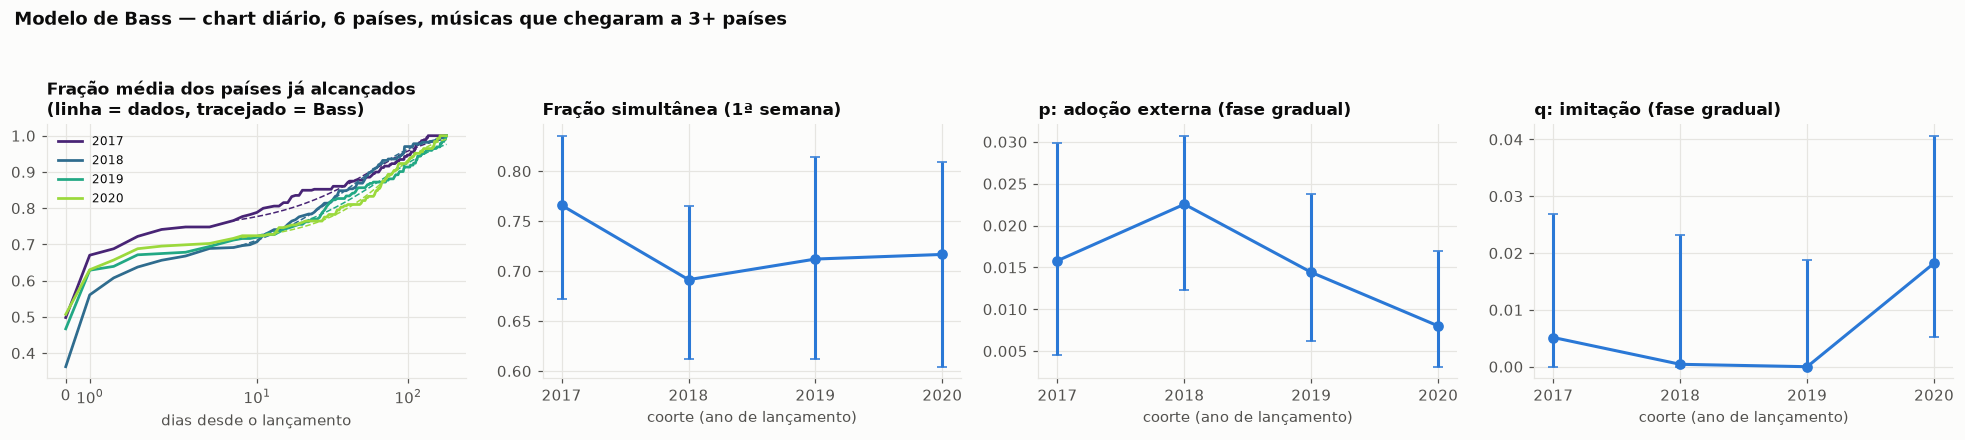

In [3]:
def barras(ax, g, par, **kw):
    ax.errorbar(g["coorte"], g[par], yerr=[np.clip(g[par] - g[f"{par}_lo"], 0, None), np.clip(g[f"{par}_hi"] - g[par], 0, None)],
                marker="o", capsize=3, **kw)

fig, axes = plt.subplots(1, 4, figsize=(18, 3.8))
ax = axes[0]
paleta = plt.cm.viridis(np.linspace(0.1, 0.85, len(curvas_d)))
for (ano, (F, s, p, q)), c in zip(curvas_d.items(), paleta):
    ax.plot(grid_d, F, color=c, linewidth=1.8, label=str(ano))
    tt = grid_d[CORTE_D:]
    ax.plot(tt, s + (1 - s) * bass_F(tt - CORTE_D, p, q), color=c, linewidth=1, linestyle="--")
ax.set_xscale("symlog", linthresh=7); ax.set_xlabel("dias desde o lançamento")
ax.set_title("Fração média dos países já alcançados\n(linha = dados, tracejado = Bass)", loc="left"); ax.legend(fontsize=8)
for ax, par, tit in [(axes[1], "simultaneo", "Fração simultânea (1ª semana)"),
                     (axes[2], "p", "p: adoção externa (fase gradual)"), (axes[3], "q", "q: imitação (fase gradual)")]:
    barras(ax, bass_d, par, color=COR["s1"])
    ax.set_xticks(bass_d["coorte"]); ax.set_title(tit, loc="left"); ax.set_xlabel("coorte (ano de lançamento)")
fig.suptitle(f"Modelo de Bass — chart diário, {len(PAISES_DIF)} países, músicas que chegaram a {MIN_PAISES}+ países",
             x=0.01, ha="left", fontweight="bold", y=1.04)
fig.tight_layout(); fig.savefig(PASTA_RES / "difusao_bass_diario.png"); plt.show()

## 2. Bass nos charts de 4 semanas (2018–2025) e calibração

Nos charts de 4 semanas, a data de entrada é a primeira **amostra** em que a música aparece. Para saber quanto
isso distorce p e q, aplicamos a mesma amostragem ao chart diário (a entrada passa a ser a primeira data de
amostra depois da entrada real) e comparamos, nas coortes em que as duas bases se sobrepõem:

- **diário** × **diário amostrado**: quanto a resolução grosseira, sozinha, muda as estimativas;
- **diário amostrado** × **4 semanas**: se as duas bases concordam quando medidas do mesmo jeito.

Se a amostragem preserva a **ordem** entre coortes, a tendência de 2018–2025 nos charts de 4 semanas é
interpretável, mesmo que os níveis de p e q não sejam comparáveis aos do diário.

/tmp/ipykernel_36884/725542202.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = T.notna().sum(1)


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),
/tmp/ipykernel_36884/725542202.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = T.notna().sum(1)


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),
/tmp/ipykernel_36884/725542202.py:41: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  m = T.notna().sum(1)


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


/tmp/ipykernel_36884/725542202.py:58: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  linhas.append({"base": rotulo, "coorte": ano, "musicas": len(Ta), "alcance_medio": Ta.notna().sum(1).mean(),


simultaneo                                  p                           \
base    4 semanas  diário diário amostrado 4 semanas  diário diário amostrado   
coorte                                                                          
2018       0.6771  0.8211           0.7202    0.0216  0.0212           0.0240   
2019       0.6698  0.7947           0.7380    0.0210  0.0113           0.0187   
2020       0.7208  0.7754           0.7337    0.0072  0.0092           0.0079   

               q                            musicas                          
base   4 semanas  diário diário amostrado 4 semanas diário diário amostrado  
coorte                                                                       
2018      0.0000  0.0000           0.0000      32.0   38.0             38.0  
2019      0.0000  0.0061           0.0000      43.0   47.0             46.0  
2020      0.0215  0.0203           0.0224      40.0   46.0             46.0

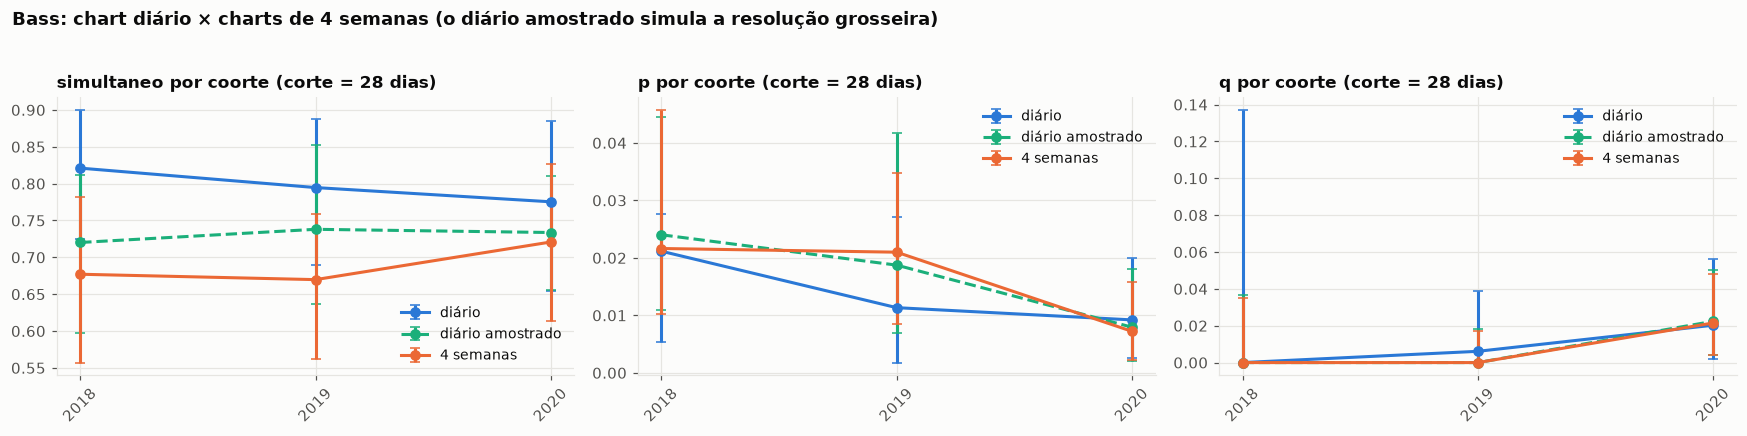

Tendência nos charts de 4 semanas (coortes 2019–2025):


,inclinacao,ic95_lo,ic95_hi,p
simultaneo,NaN,NaN,NaN,NaN
pct_graduais,NaN,NaN,NaN,NaN
p,NaN,NaN,NaN,NaN
q,NaN,NaN,NaN,NaN
q_sobre_p,NaN,NaN,NaN,NaN
alcance_medio,NaN,NaN,NaN,NaN


In [4]:
# entrada observada = primeira data de amostra >= entrada real (supõe que a música ainda está no chart)
e_am = e.copy()
k = np.searchsorted(AMOSTRAS, e_am["primeira"].to_numpy())
e_am = e_am[k < len(AMOSTRAS)]
e_am["primeira"] = AMOSTRAS[k[k < len(AMOSTRAS)]]
ini_4s = pd.Timestamp(AMOSTRAS[0])
T_da, lc_da = matriz_adocao(e_am, "primeira", ini_4s, FIM_DIARIO)

w_ent = w.groupby(["cc", "chave", "track_id"])["week_end"].min().reset_index()
T_4, lc_4 = matriz_adocao(w_ent, "week_end", ini_4s, FIM_4S)

# todas as bases com o mesmo corte de 28 dias, para comparar like with like
bass_da, _ = bass_por_coorte(T_da, lc_da, grid_d, "diário amostrado", CORTE_4S)
bass_4, curvas_4 = bass_por_coorte(T_4, lc_4, grid_d, "4 semanas", CORTE_4S)
bass_d_sob, _ = bass_por_coorte(T_d[lc_d >= ini_4s], lc_d[lc_d >= ini_4s], grid_d, "diário", CORTE_4S)
calib = pd.concat([bass_d_sob, bass_da, bass_4[bass_4["coorte"] <= FIM_DIARIO.year]])
display(calib.pivot(index="coorte", columns="base", values=["simultaneo", "p", "q", "musicas"]).round(4))

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
for ax, par in zip(axes, ["simultaneo", "p", "q"]):
    for base, cor, est in [("diário", COR["s1"], "-"), ("diário amostrado", COR["s3"], "--"), ("4 semanas", COR["s2"], "-")]:
        g = bass_4 if base == "4 semanas" else calib[calib["base"] == base]
        barras(ax, g, par, color=cor, linestyle=est, label=base)
    ax.set_title(f"{par} por coorte (corte = {CORTE_4S} dias)", loc="left"); ax.set_xticks(sorted(bass_4["coorte"])); ax.legend(fontsize=9)
    ax.tick_params(axis="x", rotation=45)
fig.suptitle("Bass: chart diário × charts de 4 semanas (o diário amostrado simula a resolução grosseira)",
             x=0.01, ha="left", fontweight="bold", y=1.03)
fig.tight_layout(); fig.savefig(PASTA_RES / "difusao_bass_4semanas.png"); plt.show()

anos_t = bass_4["coorte"].between(2019, 2025)       # 2018 começa em maio; 2026 está incompleto
t_bass = pd.DataFrame({par: tendencia(bass_4.loc[anos_t, "coorte"], bass_4.loc[anos_t, par])
                       for par in ["simultaneo", "pct_graduais", "p", "q", "q_sobre_p", "alcance_medio"]}).T
print("Tendência nos charts de 4 semanas (coortes 2019–2025):")
display(t_bass.round(5))

## 3. Rede de liderança: quem adota antes de quem?

Para cada par de países (i, j) e cada música que entrou nos dois em até `H_DIAS` (chart diário), contamos em
quantas i entrou **antes** de j e vice-versa (empates no mesmo dia ficam de fora). Um teste binomial com correção
FDR (Benjamini–Hochberg) decide se a diferença é real. Aresta i → j = "i costuma adotar antes de j".

**Ressalva:** liderar não é causar. Um país sai na frente com músicas dos próprios artistas, e fuso horário e dia
de publicação do chart podem dar 1 dia de vantagem. Os blocos e períodos são comparados entre si, não lidos como
influência pura.

353 músicas em 2+ países | 12 arestas significativas (FDR 5%)


/tmp/ipykernel_36884/655862427.py:25: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  T_lid = T_d[T_d.notna().sum(1) >= 2]
/tmp/ipykernel_36884/655862427.py:34: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  lider = pd.DataFrame({"saldo_lideranca": liq.mean(1), "pagerank_lider": pd.Series(pr),
/tmp/ipykernel_36884/655862427.py:35: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "lidera_sig": (sig & (liq > 0)).sum(1), "segue_sig": (sig & (liq < 0)).sum(1)}).sort_values("saldo_lideranca", ascending=False)
/tmp/ipykernel_36884/655862427.py:35: Pandas4Warning: Starting with pandas version 4.0 all arguments of sum will be keyword-only.
  "lidera_sig": (sig & (liq > 0)).sum(1), "segue_sig": (sig & (liq < 0)).sum(1)}).sort_values("saldo_lideranca", ascending=False)


,saldo_lideranca,pagerank_lider,lidera_sig,segue_sig,bloco
us,0.458,0.386,5,0,anglo
au,0.411,0.241,4,1,anglo
es,0.081,0.134,3,2,hispano
mx,-0.263,0.080,0,3,hispano
jp,-0.326,0.080,0,3,japonês
br,-0.361,0.080,0,3,luso


,saldo_lideranca,pagerank_lider,lidera_sig,segue_sig,bloco
us,0.458,0.386,5,0,anglo
au,0.411,0.241,4,1,anglo
es,0.081,0.134,3,2,hispano
mx,-0.263,0.080,0,3,hispano
jp,-0.326,0.080,0,3,japonês
br,-0.361,0.080,0,3,luso


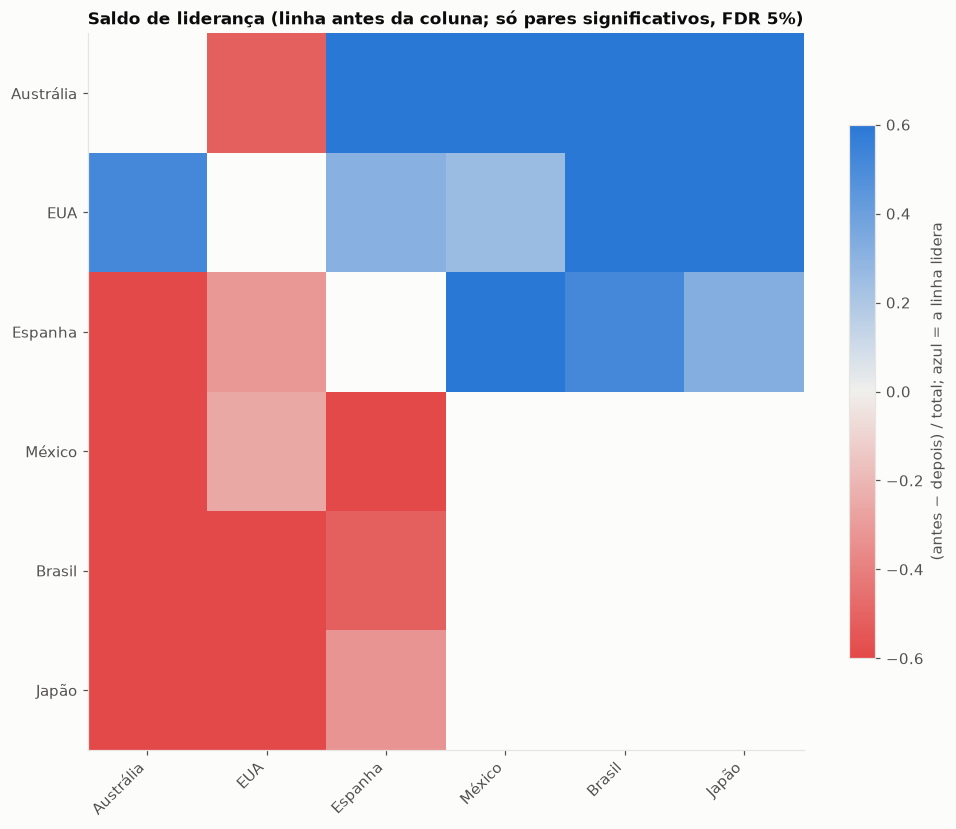

/tmp/ipykernel_36884/655862427.py:63: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  lider_per[rot] = lq.mean(1)
/tmp/ipykernel_36884/655862427.py:63: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  lider_per[rot] = lq.mean(1)


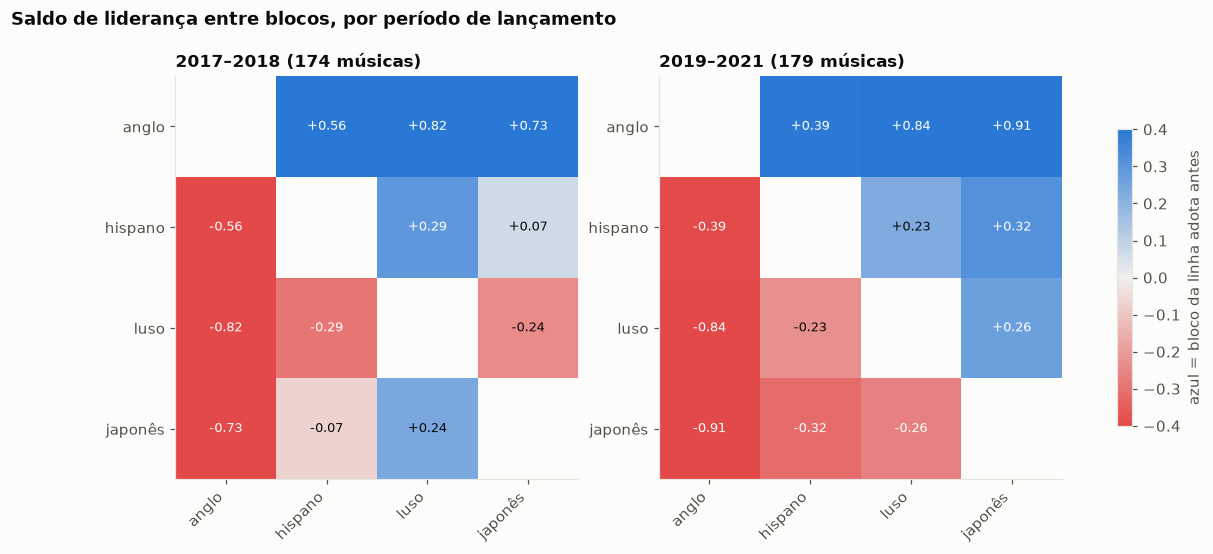

Saldo de liderança por país e período (maiores mudanças):


,2017–2018,2019–2021,mudanca
cc,,,
jp,-0.226,-0.452,-0.226
us,0.501,0.422,-0.079
es,0.085,0.075,-0.010
au,0.392,0.423,0.031
br,-0.410,-0.312,0.098
us,0.501,0.422,-0.079
es,0.085,0.075,-0.010
au,0.392,0.423,0.031
br,-0.410,-0.312,0.098


In [5]:
def lideranca(T):
    A = T.to_numpy()
    n = A.shape[1]
    antes = np.zeros((n, n), int)
    for i in range(n):
        for j in range(n):
            if i != j:
                ok = ~np.isnan(A[:, i]) & ~np.isnan(A[:, j])
                antes[i, j] = (A[ok, i] < A[ok, j]).sum()
    I, J = np.triu_indices(n, 1)
    tot = antes[I, J] + antes[J, I]
    pv = np.array([binomtest(antes[i, j], t, 0.5).pvalue if t > 0 else 1.0 for i, j, t in zip(I, J, tot)])
    # Benjamini–Hochberg
    o = np.argsort(pv); m = len(pv)
    adj = np.minimum.accumulate((pv[o] * m / np.arange(1, m + 1))[::-1])[::-1]
    padj = np.empty(m); padj[o] = np.minimum(adj, 1)
    liq = np.zeros((n, n))
    with np.errstate(invalid="ignore"):
        liq[I, J] = (antes[I, J] - antes[J, I]) / tot
    liq[J, I] = -liq[I, J]
    sig = np.zeros((n, n), bool); sig[I, J] = padj < FDR; sig[J, I] = sig[I, J]
    return pd.DataFrame(liq, index=T.columns, columns=T.columns), pd.DataFrame(sig, index=T.columns, columns=T.columns), antes


T_lid = T_d[T_d.notna().sum(1) >= 2]
liq, sig, _ = lideranca(T_lid)
G = nx.DiGraph()
G.add_nodes_from(PAISES_DIF)
for i in PAISES_DIF:
    for j in PAISES_DIF:
        if sig.loc[i, j] and liq.loc[i, j] > 0:
            G.add_edge(j, i, weight=liq.loc[i, j])      # seguidor -> líder: PageRank alto = quem é seguido
pr = nx.pagerank(G, weight="weight")
lider = pd.DataFrame({"saldo_lideranca": liq.mean(1), "pagerank_lider": pd.Series(pr),
                      "lidera_sig": (sig & (liq > 0)).sum(1), "segue_sig": (sig & (liq < 0)).sum(1)}).sort_values("saldo_lideranca", ascending=False)
lider["bloco"] = lider.index.map(BLOCO_PAIS)
print(f"{len(T_lid)} músicas em 2+ países | {G.number_of_edges()} arestas significativas (FDR {FDR:.0%})")
display(lider.round(3).head(12)); display(lider.round(3).tail(6))

fig, ax = plt.subplots(figsize=(10.5, 9))
Lm = liq.where(sig)
im = plota_matriz(Lm, "Saldo de liderança (linha antes da coluna; só pares significativos, FDR 5%)", ax, DIV, vmin=-0.6, vmax=0.6, anotar=False)
fig.colorbar(im, ax=ax, shrink=0.7, label="(antes − depois) / total; azul = a linha lidera")
fig.savefig(PASTA_RES / "difusao_lideranca_matriz.png"); plt.show()

# liderança por bloco e por período
blocos_pres = [b for b in ORDEM_BLOCOS if b in set(BLOCO_PAIS[c] for c in PAISES_DIF)]
def saldo_blocos(liq_):
    M = pd.DataFrame(np.nan, index=blocos_pres, columns=blocos_pres)
    for a in blocos_pres:
        for b in blocos_pres:
            if a != b:
                ia = [c for c in PAISES_DIF if BLOCO_PAIS[c] == a]; ib = [c for c in PAISES_DIF if BLOCO_PAIS[c] == b]
                M.loc[a, b] = np.nanmean(liq_.loc[ia, ib].values)
    return M

per = {"2017–2018": (2017, 2018), "2019–2021": (2019, 2021)}
fig, axes = plt.subplots(1, len(per), figsize=(13, 5))
lider_per = {}
for ax, (rot, (a0, a1)) in zip(axes, per.items()):
    Tp = T_lid[lc_d.reindex(T_lid.index).dt.year.between(a0, a1)]
    lq, sg, _ = lideranca(Tp)
    lider_per[rot] = lq.mean(1)
    im = plota_matriz(saldo_blocos(lq), f"{rot} ({len(Tp)} músicas)", ax, DIV, vmin=-0.4, vmax=0.4, fmt="{:+.2f}")
fig.colorbar(im, ax=axes, shrink=0.7, label="azul = bloco da linha adota antes")
fig.suptitle("Saldo de liderança entre blocos, por período de lançamento", x=0.01, ha="left", fontweight="bold")
fig.savefig(PASTA_RES / "difusao_lideranca_blocos.png"); plt.show()
lider_per = pd.DataFrame(lider_per)
lider_per["mudanca"] = lider_per.iloc[:, -1] - lider_per.iloc[:, 0]
print("Saldo de liderança por país e período (maiores mudanças):")
display(lider_per.sort_values("mudanca").round(3).iloc[np.r_[0:5, -5:0]])

## 4. O que faz uma música atravessar a barreira do idioma?

Amostra: as músicas do top 40 anual dos 6 países (as que têm letra e escore de toxicidade), lançadas depois do
início dos charts de 4 semanas e com 1 ano de observação. Resultado: em quantos dos países ela entrou no Top 200
em até 1 ano, **separando países da mesma língua da música e de outra língua**.

Modelo de Poisson com erro-padrão robusto (HC1) e *offset* = log do número de países possíveis. Os coeficientes
são razões de taxa (IRR): IRR = 0,8 significa alcançar 20% menos países.

**Só músicas em inglês e espanhol entram nos modelos.** Português e japonês praticamente nunca saem da própria
língua (média de 0,09 e 0 países de outra língua): não há variação para explicar, e o modelo teria separação
perfeita. Eles aparecem na tabela descritiva.

- `tox_z`: toxicidade padronizada (escore principal do `pipelineToxicidade`).
- `log_prior`: popularidade prévia do artista principal (entradas em charts no ano anterior). É o controle mais
  importante: artistas grandes alcançam mais países e têm mais músicas explícitas (rap americano).

**Hipótese:** a toxicidade atrapalha a travessia para **outras línguas** (IRR < 1 no modelo "outra língua") mas
não dentro da própria língua, onde a letra é entendida no contexto do gênero.

In [6]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

letras = fd[fd["cc"].isin(PAISES_DIF)]                # finalData.csv (lido na primeira célula)
L = letras.drop_duplicates("chave").set_index("chave")[["track_id", "title", "artists", "idioma"]]
L["idioma"] = L["idioma"].map(idioma_simples)

arq_tox = Path(os.environ.get("ARQ_TOX", RAIZ / "dados" / "toxicidade.csv"))
TEM_TOX = arq_tox.exists()
if TEM_TOX:
    tx = pd.read_csv(arq_tox).drop_duplicates("chave").set_index("chave")
    L = L.join(tx[["tox", "tox_max", "toxica"]])
    print(f"toxicidade lida de {arq_tox.name}: {L['tox'].notna().sum()} músicas com escore")
else:
    print("dados/toxicidade.csv não existe: rode o pipelineToxicidade.ipynb. Os modelos abaixo rodam sem toxicidade.")

# alcance nos charts de 4 semanas
pri = w.groupby("chave")["week_end"].min()
ini_obs = pd.Timestamp(AMOSTRAS[0]) + pd.Timedelta(days=28)
L["primeira"] = L.index.map(pri)
L["lanc"] = L["track_id"].map(lanc)
amostra = L.dropna(subset=["primeira"])
amostra = amostra[(amostra["primeira"] >= ini_obs) & (amostra["primeira"] <= FIM_4S - pd.Timedelta(days=JANELA_ALC))
                  & ~(amostra["lanc"] < pd.Timestamp(AMOSTRAS[0]))]     # lançada antes dos charts = censura à esquerda
jan = w[w["chave"].isin(amostra.index)].merge(amostra[["primeira"]], left_on="chave", right_index=True)
jan = jan[jan["week_end"] <= jan["primeira"] + pd.Timedelta(days=JANELA_ALC)]
paises_mus = jan.groupby("chave")["cc"].agg(set)
amostra = amostra.join(paises_mus.rename("paises"))
lingua = pd.Series(LINGUA_PAIS)
amostra["n_mesma"] = [sum(LINGUA_PAIS[c] == i for c in p) for p, i in zip(amostra["paises"], amostra["idioma"])]
amostra["n_outra"] = amostra["paises"].map(len) - amostra["n_mesma"]
amostra["poss_mesma"] = amostra["idioma"].map(lambda i: sum(LINGUA_PAIS[c] == i for c in PAISES_DIF))
amostra["poss_outra"] = len(PAISES_DIF) - amostra["poss_mesma"]
amostra["ano"] = amostra["primeira"].dt.year

# popularidade prévia do artista principal: entradas (país × semana) no ano anterior à 1ª aparição
art = w_pop.dropna(subset=["artist_uris"]).assign(a1=lambda x: x["artist_uris"].str.split("|").str[0].str.strip())
a_mus = art.drop_duplicates("chave").set_index("chave")["a1"]
amostra["artista"] = amostra.index.map(a_mus)
ent_art = art.groupby(["a1", "week_end"]).size().rename("n").reset_index()
def prior(a, t):
    g = ent_art[ent_art["a1"] == a]
    return g.loc[(g["week_end"] < t) & (g["week_end"] >= t - pd.Timedelta(days=365)), "n"].sum()
amostra["log_prior"] = np.log1p([prior(a, t) for a, t in zip(amostra["artista"], amostra["primeira"])])
amostra = amostra[amostra["idioma"].isin(["en", "es", "pt", "ja"]) & (amostra["poss_mesma"] > 0)]
print(f"{len(amostra)} músicas na amostra | por idioma: {amostra['idioma'].value_counts().to_dict()}")
desc = amostra.groupby("idioma")[["n_mesma", "poss_mesma", "n_outra", "poss_outra"]].mean()
if "tox" in amostra:
    desc = desc.join(amostra.groupby("idioma")[["tox", "toxica"]].mean())
display(desc.round(2))

toxicidade lida de toxicidade.csv: 1391 músicas com escore


1020 músicas na amostra | por idioma: {'es': 387, 'en': 269, 'pt': 255, 'ja': 109}


,n_mesma,poss_mesma,n_outra,poss_outra,tox,toxica
idioma,,,,,,
en,1.83,2.0,1.78,4.0,0.36,0.431227
es,1.45,2.0,0.39,4.0,0.43,0.521964
ja,1.00,1.0,0.00,5.0,0.17,0.247706
pt,1.00,1.0,0.01,5.0,0.47,0.584314


In [7]:
def poisson(y, offset_col, dados, termos):
    f = f"{y} ~ {termos}"
    m = smf.glm(f, data=dados, family=sm.families.Poisson(), offset=np.log(dados[offset_col])).fit(cov_type="HC1")
    t = pd.DataFrame({"IRR": np.exp(m.params), "IC_lo": np.exp(m.conf_int()[0]), "IC_hi": np.exp(m.conf_int()[1]),
                      "p": m.pvalues})
    return m, t.drop(index=[i for i in t.index if i.startswith("C(ano)") or i == "Intercept"])

base = "ingles + log_prior + C(ano)"
modelos = {}
am = amostra[amostra["idioma"].isin(["en", "es"])].assign(ingles=lambda x: (x["idioma"] == "en").astype(int))
if TEM_TOX and am["tox"].notna().sum() > 50:
    am = am.dropna(subset=["tox"]).copy()
    am["tox_z"] = (am["tox"] - am["tox"].mean()) / am["tox"].std()
    for y, off in [("n_outra", "poss_outra"), ("n_mesma", "poss_mesma")]:
        modelos[f"{y} | tox"] = poisson(y, off, am, f"tox_z + {base}")
        # moderação: o efeito da toxicidade é diferente para músicas em inglês? (tox_z = efeito no espanhol)
        modelos[f"{y} | tox × inglês"] = poisson(y, off, am, f"tox_z * ingles + log_prior + C(ano)")
else:
    for y, off in [("n_outra", "poss_outra"), ("n_mesma", "poss_mesma")]:
        modelos[f"{y} | sem tox"] = poisson(y, off, am, base)
for nome, (m, t) in modelos.items():
    print(f"\n{nome}  (n = {int(m.nobs)})")
    display(t.round(3))

# robustez: a flag explicit do Spotify no lugar do escore (só faixas até 2021)
am_ex = am.assign(explicit=am["track_id"].map(explicit)).dropna(subset=["explicit"])
am_ex["explicit"] = am_ex["explicit"].astype(str).str.lower().isin(["true", "1"]).astype(int)
if am_ex["explicit"].nunique() == 2 and len(am_ex) > 50:
    for y, off in [("n_outra", "poss_outra"), ("n_mesma", "poss_mesma")]:
        m, t = poisson(y, off, am_ex, f"explicit + {base}")
        modelos[f"{y} | explicit"] = (m, t)
        print(f"\n{y} | explicit do Spotify (n = {int(m.nobs)})"); display(t.round(3))

tab_alc = pd.concat({k: v[1] for k, v in modelos.items()}, names=["modelo", "termo"]).reset_index()


n_outra | tox  (n = 656)


,IRR,IC_lo,IC_hi,p
tox_z,0.953,0.873,1.041,0.285
ingles,4.481,3.670,5.472,0.000
log_prior,1.127,1.070,1.187,0.000



n_outra | tox × inglês  (n = 656)


,IRR,IC_lo,IC_hi,p
tox_z,1.304,1.119,1.521,0.001
ingles,4.636,3.751,5.729,0.000
tox_z:ingles,0.679,0.564,0.817,0.000
log_prior,1.123,1.067,1.182,0.000



n_mesma | tox  (n = 656)


,IRR,IC_lo,IC_hi,p
tox_z,1.059,1.037,1.082,0.0
ingles,1.280,1.225,1.338,0.0
log_prior,1.032,1.020,1.045,0.0


... (2 outputs left out)


n_outra | explicit do Spotify (n = 361)


,IRR,IC_lo,IC_hi,p
explicit,0.793,0.633,0.993,0.043
ingles,6.832,4.991,9.353,0.000
log_prior,1.106,1.039,1.178,0.002



n_mesma | explicit do Spotify (n = 361)


,IRR,IC_lo,IC_hi,p
explicit,1.156,1.091,1.226,0.0
ingles,1.147,1.077,1.223,0.0
log_prior,1.037,1.021,1.053,0.0


## 5. Semântica × difusão

Modelo **diádico** (música × país de destino) nos 6 países com letra. Para cada música, a **origem** é o país (dos 6)
onde ela aparece primeiro; os destinos são os outros 5. Resultado: a música entrou no Top 200 do destino em até 1 ano?

- `prox_sem`: cosseno entre a letra (traduzida, LaBSE) e o centroide do top 40 do destino **no ano anterior**
  (sem a própria música), padronizado. Se positivo, músicas "parecidas com o gosto" do destino entram mais: a
  semelhança de conteúdo vira canal de difusão, o que liga a convergência semântica à difusão.
- `mesma_lingua`: a música está na língua do destino.
- Efeitos fixos de origem, destino e ano; erro-padrão agrupado por música.

**Ressalva de seleção:** todas as músicas estão no top 40 de pelo menos um dos 6 países, então o modelo compara
hits entre si, não hits com músicas comuns.

embeddings encontrados para 1391 de 1392 músicas


5100 pares música × destino | 1020 músicas | taxa de entrada 20.2%
Logit diádico (n = 5100, pseudo-R² = 0.469); OR = razão de chances


,OR,IC_lo,IC_hi,p
prox_sem,1.217,1.025,1.444,0.025
tox_z,0.934,0.793,1.099,0.411
mesma_lingua,16.778,10.334,27.238,0.000
tox_z:mesma_lingua,1.722,1.320,2.246,0.000
log_prior,1.233,1.141,1.333,0.000


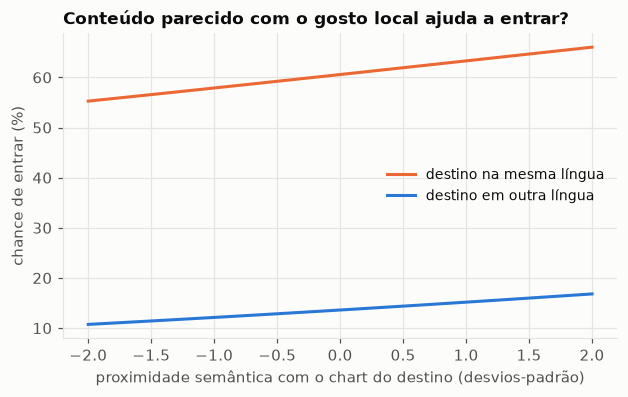

In [8]:
arq_emb = RAIZ / "dados" / "embeddings" / "sentence_transformers_LaBSE__traducao_en.npz"
tab_dia = None
if not arq_emb.exists():
    print(f"{arq_emb} não existe: rode o pipelineAnalise.ipynb primeiro (ele gera os embeddings).")
else:
    z = np.load(arq_emb)
    vet = dict(zip(z["chaves"].tolist(), z["emb"]))
    lt = letras.dropna(subset=["letra_en_limpa"]).drop_duplicates("track_id")
    emb = {}
    for tid, txt, ch in zip(lt["track_id"], lt["letra_en_limpa"], lt["chave"]):
        k = f"{tid}:{hashlib.md5(txt.encode('utf-8')).hexdigest()[:10]}"
        if k in vet:
            emb.setdefault(ch, vet[k])
    print(f"embeddings encontrados para {len(emb)} de {letras['chave'].nunique()} músicas")

    cel = letras[letras["chave"].isin(emb)].groupby(["cc", "year"])["chave"].agg(list)
    def centroide(cc, ano, sem):
        if (cc, ano) not in cel.index:
            return None
        v = np.stack([emb[c] for c in cel[(cc, ano)] if c != sem])
        v = v.mean(0)
        return v / np.linalg.norm(v)

    primeira_cc = w[w["cc"].isin(PAISES)].groupby(["chave", "cc"])["week_end"].min()
    linhas = []
    for ch, r in amostra[amostra.index.isin(emb)].iterrows():
        if ch not in primeira_cc.index.get_level_values(0):
            continue
        pc = primeira_cc.loc[ch]
        origem = pc.idxmin()
        for dest in PAISES:
            if dest == origem:
                continue
            c = centroide(dest, r["ano"] - 1, ch)
            if c is None:
                continue
            linhas.append({"chave": ch, "origem": origem, "destino": dest, "ano": r["ano"],
                           "entrou": int(dest in r["paises"]), "cos": float(emb[ch] @ c),
                           "mesma_lingua": int(LINGUA_PAIS[dest] == r["idioma"]), "log_prior": r["log_prior"],
                           "tox": r["tox"] if "tox" in r else np.nan})
    dia = pd.DataFrame(linhas)
    dia["prox_sem"] = (dia["cos"] - dia["cos"].mean()) / dia["cos"].std()
    print(f"{len(dia)} pares música × destino | {dia['chave'].nunique()} músicas | taxa de entrada {dia['entrou'].mean():.1%}")

    termos = "prox_sem + mesma_lingua + log_prior + C(origem) + C(destino) + C(ano)"
    if TEM_TOX and dia["tox"].notna().sum() > 100:
        dia = dia.dropna(subset=["tox"])
        dia["tox_z"] = (dia["tox"] - dia["tox"].mean()) / dia["tox"].std()
        termos = "prox_sem + tox_z * mesma_lingua + log_prior + C(origem) + C(destino) + C(ano)"
    grupos = pd.factorize(dia["chave"])[0]
    m_dia = smf.logit(f"entrou ~ {termos}", data=dia).fit(disp=0, cov_type="cluster", cov_kwds={"groups": grupos})
    ci = m_dia.conf_int()
    tab_dia = pd.DataFrame({"OR": np.exp(m_dia.params), "IC_lo": np.exp(ci[0]), "IC_hi": np.exp(ci[1]), "p": m_dia.pvalues})
    tab_dia = tab_dia.drop(index=[i for i in tab_dia.index if i.startswith("C(") or i == "Intercept"])
    print(f"Logit diádico (n = {int(m_dia.nobs)}, pseudo-R² = {m_dia.prsquared:.3f}); OR = razão de chances")
    display(tab_dia.round(3))

    # efeito marginal da proximidade semântica, por mesma/outra língua
    fig, ax = plt.subplots(figsize=(6.5, 3.6))
    xs = np.linspace(-2, 2, 41)
    for ml, cor, rot in [(1, COR["s2"], "destino na mesma língua"), (0, COR["s1"], "destino em outra língua")]:
        base_df = dia[dia["mesma_lingua"] == ml]
        ys = [m_dia.predict(base_df.assign(prox_sem=x)).mean() for x in xs]
        ax.plot(xs, np.array(ys) * 100, color=cor, label=rot)
    ax.set_xlabel("proximidade semântica com o chart do destino (desvios-padrão)")
    ax.set_ylabel("chance de entrar (%)"); ax.legend(fontsize=9)
    ax.set_title("Conteúdo parecido com o gosto local ajuda a entrar?", loc="left")
    fig.savefig(PASTA_RES / "difusao_semantica.png"); plt.show()

In [9]:
bass_d.to_csv(PASTA_RES / "difusao_bass_diario.csv", index=False)
pd.concat([calib, bass_4[bass_4["coorte"] > FIM_DIARIO.year]]).to_csv(PASTA_RES / "difusao_bass_calibracao.csv", index=False)
t_bass.to_csv(PASTA_RES / "difusao_bass_tendencia.csv")
lider.to_csv(PASTA_RES / "difusao_lideranca_paises.csv")
lider_per.to_csv(PASTA_RES / "difusao_lideranca_periodos.csv")
tab_alc.to_csv(PASTA_RES / "difusao_alcance_modelos.csv", index=False)
if tab_dia is not None:
    tab_dia.to_csv(PASTA_RES / "difusao_semantica_logit.csv")

print(f"H_DIAS = {H_DIAS} | N_BOOT_BASS = {N_BOOT} | {len(PAISES_DIF)} países")
print("Bass diário — fração simultânea:", dict(zip(bass_d["coorte"], bass_d["simultaneo"].round(3))),
      "| q:", dict(zip(bass_d["coorte"], bass_d["q"].round(4))))
print("Bass 4 semanas — fração simultânea:", dict(zip(bass_4["coorte"], bass_4["simultaneo"].round(3))),
      "| q:", dict(zip(bass_4["coorte"], bass_4["q"].round(4))))
for k, t in t_bass.iterrows():
    print(f"  tendência {k:<14} {t['inclinacao']:+.5f}/ano [IC95% {t['ic95_lo']:+.5f}, {t['ic95_hi']:+.5f}] p={t['p']:.3f}")
print("Líderes (saldo):", " > ".join(lider.index[:6].str.upper()), "| seguidores:", " < ".join(lider.index[-4:].str.upper()))

H_DIAS = 180 | N_BOOT_BASS = 200 | 6 países
Bass diário — fração simultânea: {2017: 0.766, 2018: 0.691, 2019: 0.712, 2020: 0.717} | q: {2017: 0.0051, 2018: 0.0004, 2019: 0.0, 2020: 0.0182}
Bass 4 semanas — fração simultânea: {2018: 0.677, 2019: 0.67, 2020: 0.721} | q: {2018: 0.0, 2019: 0.0, 2020: 0.0215}
  tendência simultaneo     +nan/ano [IC95% +nan, +nan] p=nan
  tendência pct_graduais   +nan/ano [IC95% +nan, +nan] p=nan
  tendência p              +nan/ano [IC95% +nan, +nan] p=nan
  tendência q              +nan/ano [IC95% +nan, +nan] p=nan
  tendência q_sobre_p      +nan/ano [IC95% +nan, +nan] p=nan
  tendência alcance_medio  +nan/ano [IC95% +nan, +nan] p=nan
Líderes (saldo): US > AU > ES > MX > JP > BR | seguidores: ES < MX < JP < BR
